Random Forest Accuracy: 0.9607864554888039
Logistic Regression Accuracy: 0.9649371927908247
Decision Tree Accuracy: 0.959803386127799


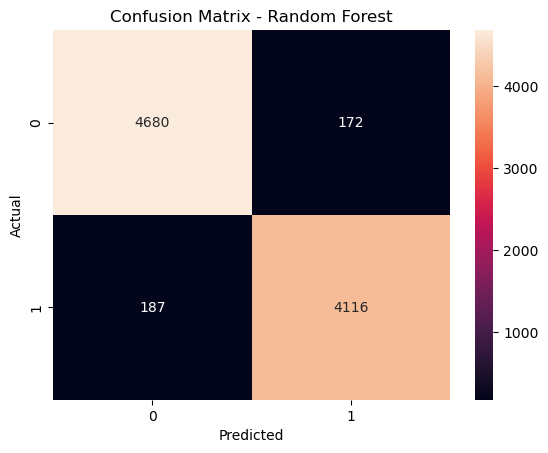

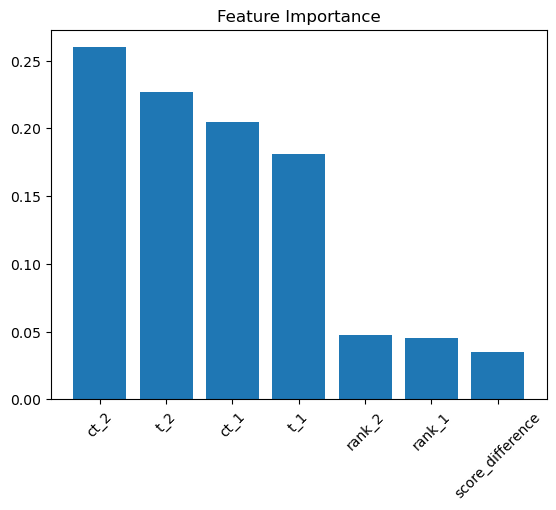

In [1]:
# ---------------------------------------------------------
# CS:GO Match Winner Prediction 
# ---------------------------------------------------------

# Import libraries
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import accuracy_score, confusion_matrix

# ---------------------------------------------------------
# Step 1: Load dataset
# ---------------------------------------------------------
data = pd.read_csv("results.csv")

# ---------------------------------------------------------
# Step 2: Feature Engineering
# ---------------------------------------------------------
data["score_difference"] = abs(data["result_1"] - data["result_2"])

features = data[[
    "rank_1", "rank_2",
    "ct_1", "t_1",
    "ct_2", "t_2",
    "score_difference"
]]

target = data["map_winner"]


# Step 4: Train-Test Split
X_train, X_test, y_train, y_test = train_test_split(
    features, target, test_size=0.2, random_state=42
)
# Step 5: RANDOM FOREST (Main Model)
rf = RandomForestClassifier(random_state=42)
rf.fit(X_train, y_train)
rf_pred = rf.predict(X_test)

rf_acc = accuracy_score(y_test, rf_pred)
print("Random Forest Accuracy:", rf_acc)

# Step 6: LOGISTIC REGRESSION
lr = LogisticRegression(max_iter=1000)
lr.fit(X_train, y_train)
lr_pred = lr.predict(X_test)

lr_acc = accuracy_score(y_test, lr_pred)
print("Logistic Regression Accuracy:", lr_acc)

# Step 7: DECISION TREE
dt = DecisionTreeClassifier(random_state=42)
dt.fit(X_train, y_train)
dt_pred = dt.predict(X_test)

dt_acc = accuracy_score(y_test, dt_pred)
print("Decision Tree Accuracy:", dt_acc)

# ---------------------------------------------------------
# Step 8: CONFUSION MATRIX (Random Forest)
# ---------------------------------------------------------
cm = confusion_matrix(y_test, rf_pred)

plt.figure()
sns.heatmap(cm, annot=True, fmt='d')
plt.title("Confusion Matrix - Random Forest")
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.show()

# ---------------------------------------------------------
# Step 9: FEATURE IMPORTANCE
# ---------------------------------------------------------
importance = rf.feature_importances_

feature_names = [
    "rank_1", "rank_2",
    "ct_1", "t_1",
    "ct_2", "t_2",
    "score_difference"
]

feat_df = pd.DataFrame({
    "Feature": feature_names,
    "Importance": importance
}).sort_values(by="Importance", ascending=False)

plt.figure()
plt.bar(feat_df["Feature"], feat_df["Importance"])
plt.xticks(rotation=45)
plt.title("Feature Importance")
plt.show()

In [1]:
# ---------------------------------------------------------
# CS:GO Match Winner Prediction Project
# Human-Friendly Random Forest ML Code
# ---------------------------------------------------------

# Import the libraries we need
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix


# ---------------------------------------------------------
# Step 1: Read the match results dataset
# ---------------------------------------------------------
# Load the CSV file into Python
data = pd.read_csv("results.csv")


# ---------------------------------------------------------
# Step 2: Create a new useful feature
# ---------------------------------------------------------
# Score difference tells us how close the match was
data["score_difference"] = abs(data["result_1"] - data["result_2"])


# ---------------------------------------------------------
# Step 3: Choose input columns for prediction
# ---------------------------------------------------------
# These columns help predict who wins the match
features = data[[
    "rank_1",
    "rank_2",
    "ct_1",
    "t_1",
    "ct_2",
    "t_2",
    "score_difference"
]]


# ---------------------------------------------------------
# Step 4: Choose target column
# ---------------------------------------------------------
# map_winner is what we want to predict
target = data["map_winner"]


# ---------------------------------------------------------
# Step 5: Split data into training and testing
# ---------------------------------------------------------
# 80% for training, 20% for testing
X_train, X_test, y_train, y_test = train_test_split(
    features,
    target,
    test_size=0.20,
    random_state=42
)


# ---------------------------------------------------------
# Step 6: Create Random Forest model
# ---------------------------------------------------------
# Random Forest is strong and easy for classification tasks
model = RandomForestClassifier(random_state=42)


# ---------------------------------------------------------
# Step 7: Train the model
# ---------------------------------------------------------
# Teach the model using training data
model.fit(X_train, y_train)


# ---------------------------------------------------------
# Step 8: Make predictions
# ---------------------------------------------------------
# Predict winners for test data
predictions = model.predict(X_test)


# ---------------------------------------------------------
# Step 9: Check model accuracy
# ---------------------------------------------------------
accuracy = accuracy_score(y_test, predictions)
print("Model Accuracy:", accuracy)


# ---------------------------------------------------------
# Step 10: Detailed performance report
# ---------------------------------------------------------
print("\nClassification Report:")
print(classification_report(y_test, predictions))


# ---------------------------------------------------------
# Step 11: Confusion Matrix
# ---------------------------------------------------------
print("\nConfusion Matrix:")
print(confusion_matrix(y_test, predictions))

Model Accuracy: 0.9607864554888039

Classification Report:
              precision    recall  f1-score   support

           1       0.96      0.96      0.96      4852
           2       0.96      0.96      0.96      4303

    accuracy                           0.96      9155
   macro avg       0.96      0.96      0.96      9155
weighted avg       0.96      0.96      0.96      9155


Confusion Matrix:
[[4680  172]
 [ 187 4116]]


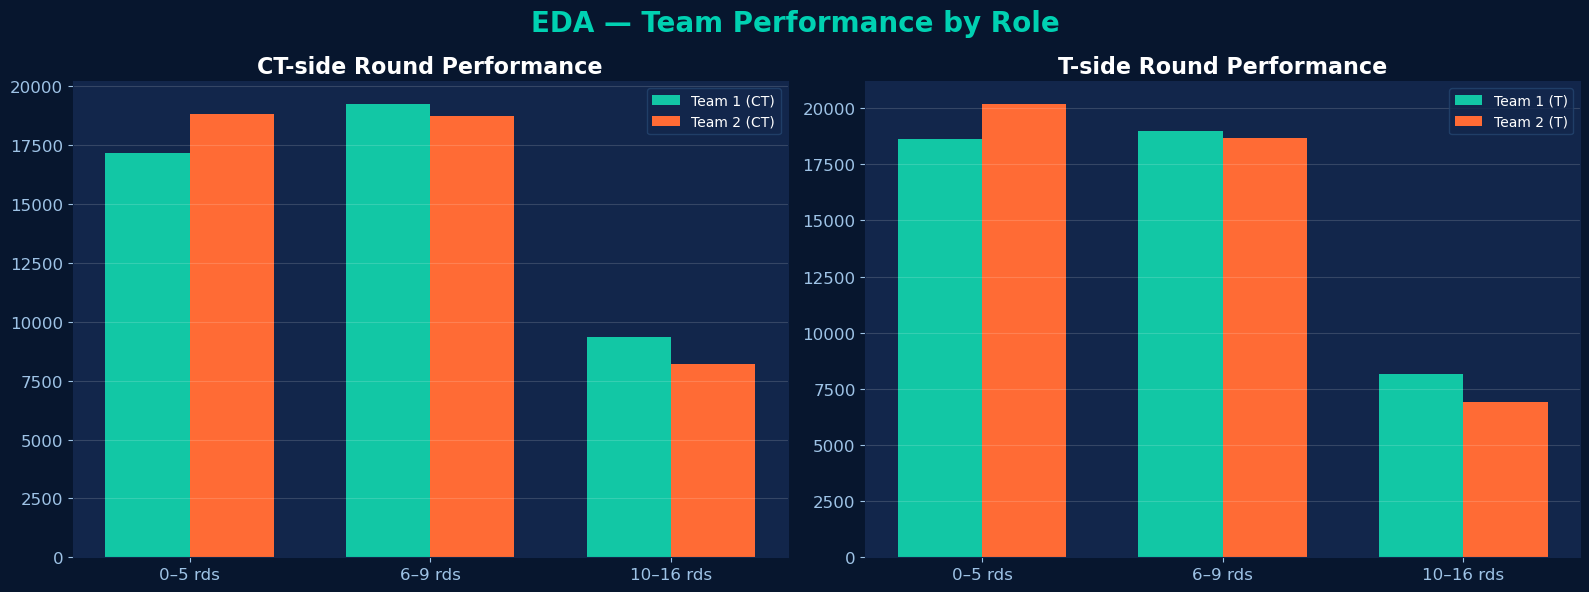

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np

data = pd.read_csv("results.csv")

# Function to convert round values into buckets
def round_bucket(x):
    if x <= 5:
        return "0–5 rds"
    elif x <= 9:
        return "6–9 rds"
    else:
        return "10–16 rds"

# Create buckets for each role column
for col in ["ct_1", "ct_2", "t_1", "t_2"]:
    data[col + "_bucket"] = data[col].apply(round_bucket)

buckets = ["0–5 rds", "6–9 rds", "10–16 rds"]

# Count values for CT side
team1_ct = data["ct_1_bucket"].value_counts().reindex(buckets, fill_value=0)
team2_ct = data["ct_2_bucket"].value_counts().reindex(buckets, fill_value=0)

# Count values for T side
team1_t = data["t_1_bucket"].value_counts().reindex(buckets, fill_value=0)
team2_t = data["t_2_bucket"].value_counts().reindex(buckets, fill_value=0)

# Dark theme
plt.style.use("dark_background")

fig, axes = plt.subplots(1, 2, figsize=(16, 6))

fig.patch.set_facecolor("#07162E")

for ax in axes:
    ax.set_facecolor("#12264B")
    ax.grid(axis="y", alpha=0.15)
    ax.tick_params(colors="#9EC3E6", labelsize=12)
    for spine in ax.spines.values():
        spine.set_color("#12264B")

x = np.arange(len(buckets))
width = 0.35

# CT-side graph
axes[0].bar(x - width/2, team1_ct, width, label="Team 1 (CT)", color="#12C7A5")
axes[0].bar(x + width/2, team2_ct, width, label="Team 2 (CT)", color="#FF6B35")
axes[0].set_title("CT-side Round Performance", fontsize=16, fontweight="bold")
axes[0].set_xticks(x)
axes[0].set_xticklabels(buckets)
axes[0].legend(facecolor="#12264B", edgecolor="#24456F")

# T-side graph
axes[1].bar(x - width/2, team1_t, width, label="Team 1 (T)", color="#12C7A5")
axes[1].bar(x + width/2, team2_t, width, label="Team 2 (T)", color="#FF6B35")
axes[1].set_title("T-side Round Performance", fontsize=16, fontweight="bold")
axes[1].set_xticks(x)
axes[1].set_xticklabels(buckets)
axes[1].legend(facecolor="#12264B", edgecolor="#24456F")

fig.suptitle("EDA — Team Performance by Role", fontsize=20, fontweight="bold", color="#00D1B2")

plt.tight_layout()
plt.savefig("team_performance_by_role.png", dpi=300, bbox_inches="tight")
plt.show()

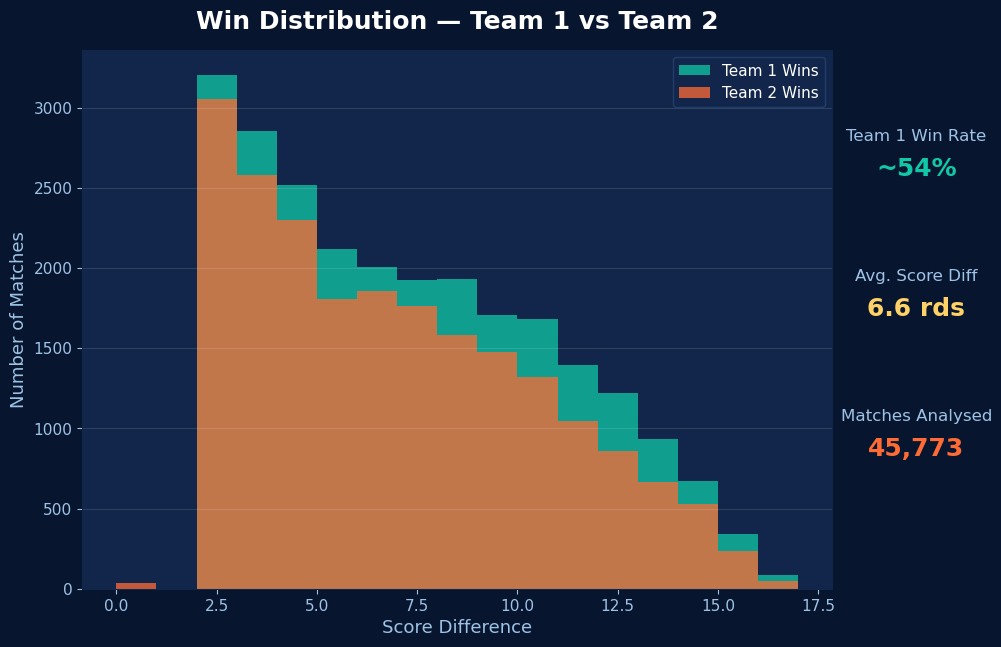

In [2]:
import pandas as pd
import matplotlib.pyplot as plt

# Load dataset
data = pd.read_csv("results.csv")

# Create score difference
data["score_difference"] = abs(data["result_1"] - data["result_2"])

# Split score difference by winner
team1_wins = data[data["map_winner"] == 1]["score_difference"]
team2_wins = data[data["map_winner"] == 2]["score_difference"]

# If your map_winner values are text, use this instead:
# team1_wins = data[data["map_winner"] == "team1"]["score_difference"]
# team2_wins = data[data["map_winner"] == "team2"]["score_difference"]

# Calculate key values
team1_win_rate = (len(team1_wins) / len(data)) * 100
avg_score_diff = data["score_difference"].mean()
matches_analysed = len(data)

# Dark theme
plt.style.use("dark_background")

fig, ax = plt.subplots(figsize=(12, 7))

fig.patch.set_facecolor("#07162E")
ax.set_facecolor("#12264B")

# Histogram
bins = range(0, 18)

ax.hist(
    team1_wins,
    bins=bins,
    alpha=0.75,
    color="#10C7A7",
    label="Team 1 Wins"
)

ax.hist(
    team2_wins,
    bins=bins,
    alpha=0.75,
    color="#FF6B35",
    label="Team 2 Wins"
)

# Title and labels
ax.set_title(
    "Win Distribution — Team 1 vs Team 2",
    fontsize=18,
    fontweight="bold",
    color="white",
    pad=15
)

ax.set_xlabel("Score Difference", fontsize=13, color="#9EC3E6")
ax.set_ylabel("Number of Matches", fontsize=13, color="#9EC3E6")

# Grid and ticks
ax.grid(axis="y", alpha=0.12)
ax.tick_params(colors="#9EC3E6", labelsize=11)

# Legend
ax.legend(
    facecolor="#12264B",
    edgecolor="#24456F",
    fontsize=11
)

# Remove borders
for spine in ax.spines.values():
    spine.set_color("#12264B")

# Add key statistics as text boxes on the right
fig.text(0.82, 0.75, "Team 1 Win Rate", fontsize=12, color="#9EC3E6", ha="center")
fig.text(0.82, 0.70, f"~{team1_win_rate:.0f}%", fontsize=18, color="#10C7A7",
         ha="center", fontweight="bold")

fig.text(0.82, 0.55, "Avg. Score Diff", fontsize=12, color="#9EC3E6", ha="center")
fig.text(0.82, 0.50, f"{avg_score_diff:.1f} rds", fontsize=18, color="#FFD166",
         ha="center", fontweight="bold")

fig.text(0.82, 0.35, "Matches Analysed", fontsize=12, color="#9EC3E6", ha="center")
fig.text(0.82, 0.30, f"{matches_analysed:,}", fontsize=18, color="#FF6B35",
         ha="center", fontweight="bold")

# Leave space on right for stats
plt.subplots_adjust(right=0.75)

# Save graph
plt.savefig("win_distribution_team1_vs_team2.png", dpi=300, bbox_inches="tight")

plt.show()